In [1]:
pip install tensorflow

In [2]:
import tensorflow as tf
tf.random.set_seed(3)
import matplotlib.pyplot as plt
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Conv2D, Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
import warnings
warnings.filterwarnings("ignore")

In [3]:
img_dir = r"D:\Data Mites Class\MLA\Capstone Projects\redatamitesteamannouncementptidcdsfeb264016\PRCP-1001-RiceLeaf\Data"
img_size = (224, 224)
batch_size = 16

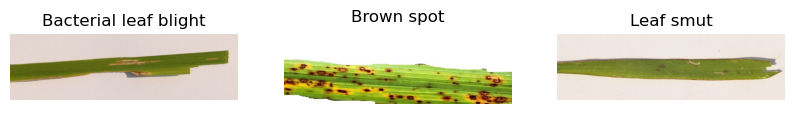

In [4]:
import os
from PIL import Image

img_dir = r"D:\Data Mites Class\MLA\Capstone Projects\redatamitesteamannouncementptidcdsfeb264016\PRCP-1001-RiceLeaf\Data"

plt.figure(figsize=(10,10))
i = 1
for class_name in os.listdir(img_dir):
    class_path = os.path.join(img_dir, class_name)
    img_name = os.listdir(class_path)[0]
    img_path = os.path.join(class_path, img_name)

    img = Image.open(img_path)

    plt.subplot(1,3,i)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis('off')
    i += 1

plt.show()

In [5]:
import os


img_dir = r"D:\Data Mites Class\MLA\Capstone Projects\redatamitesteamannouncementptidcdsfeb264016\PRCP-1001-RiceLeaf\Data"

total = 0
for class_name in os.listdir(img_dir):
    class_path = os.path.join(img_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    files = os.listdir(class_path)
    print(class_name, "->", len(files))
    total += len(files)

print("Total:", total)

Bacterial leaf blight -> 22
Brown spot -> 40
Leaf smut -> 39
Total: 101


In [6]:
data_gen = ImageDataGenerator(
    rescale = 1./255, validation_split = 0.2, rotation_range = 20, zoom_range = 0.2, 
    width_shift_range = 0.2, height_shift_range = 0.2, horizontal_flip = True
)

In [7]:
# Training Data
train_gen = data_gen.flow_from_directory(
    img_dir,
    target_size = img_size,
    batch_size = batch_size,
    class_mode = 'categorical',
    subset = 'training'
)

# Validation Data
val_gen = data_gen.flow_from_directory(
    img_dir,
    target_size = img_size,
    batch_size = batch_size,
    class_mode = 'categorical',
    subset = 'validation'
)

Found 82 images belonging to 3 classes.
Found 19 images belonging to 3 classes.


In [8]:
# viewing the class labesl:
print("Class Labels:", train_gen.class_indices)

Class Labels: {'Bacterial leaf blight': 0, 'Brown spot': 1, 'Leaf smut': 2}


In [9]:
# viewing the class data:
print(train_gen.classes)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2]


In [10]:
# Pretrained Model:
base_model = MobileNetV2(
    input_shape = (224, 224, 3),
    include_top = False,
    weights = 'imagenet'
)

base_model.trainable = False

In [11]:
# Custom Layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(64, activation = 'relu')(x)
x = Dropout(0.6)(x)
output = Dense(3, activation = 'softmax')(x)


model = Model(inputs = base_model.input, outputs = output)

In [12]:
# Prevent Overfiting
early_stop = EarlyStopping(
    monitor = 'val_loss',
    patience = 3,
    restore_best_weights = True
)

In [13]:
# compile
model.compile(
    optimizer = Adam(learning_rate = 0.001),
    loss = 'categorical_crossentropy',
    metrics = ['accuracy']
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1 (Conv2D)                │ (None, 112, 112, 32)      │             864 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bn_Conv1 (BatchNormalization) │ (None, 112, 112, 32)      │             128 │ Conv1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1_relu (ReLU)             │ (None, 112, 112, 32)      │               0 │ bn_Conv1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise       │ (None, 112, 112, 32)      │             288 │ Conv1_relu[0][0]           │
│ (DepthwiseConv2D)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_BN    │ (None, 112, 112, 32)      │             128 │ expanded_conv_depthwise[0… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_relu  │ (None, 112, 112, 32)      │               0 │ expanded_conv_depthwise_B… │
│ (ReLU)                        │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project         │ (None, 112, 112, 16)      │             512 │ expanded_conv_depthwise_r… │
│ (Conv2D)                      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project_BN      │ (None, 112, 112, 16)      │              64 │ expanded_conv_project[0][… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand (Conv2D)       │ (None, 112, 112, 96)      │           1,536 │ expanded_conv_project_BN[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_BN             │ (None, 112, 112, 96)      │             384 │ block_1_expand[0][0]       │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_relu (ReLU)    │ (None, 112, 112, 96)      │               0 │ block_1_expand_BN[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_pad (ZeroPadding2D)   │ (None, 113, 113, 96)      │               0 │ block_1_expand_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_depthwise             │ (None, 56, 56, 96)        │             864 │ block_1_pad[0][0]          │
│ (DepthwiseConv2D)             │                           │               

 Total params: 2,340,163 (8.93 MB)

 Trainable params: 82,179 (321.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
# training
history = model.fit(
    train_gen,
    epochs = 15,
    validation_data = val_gen,
    callbacks = [early_stop]
)

Epoch 1/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.4756 - loss: 1.3082 - val_accuracy: 0.5789 - val_loss: 0.9604
Epoch 2/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 887ms/step - accuracy: 0.4756 - loss: 1.3961 - val_accuracy: 0.5789 - val_loss: 0.8100
Epoch 3/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 944ms/step - accuracy: 0.5732 - loss: 1.0972 - val_accuracy: 0.8421 - val_loss: 0.6269
Epoch 4/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 955ms/step - accuracy: 0.6951 - loss: 0.7224 - val_accuracy: 0.6316 - val_loss: 0.7632
Epoch 5/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 942ms/step - accuracy: 0.5732 - loss: 0.8369 - val_accuracy: 0.7895 - val_loss: 0.5878
Epoch 6/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 916ms/step - accuracy: 0.6341 - loss: 0.7727 - val_accuracy: 0.8421 - val_loss: 0.5854
Epoch 7/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 921ms/step - accuracy: 0.6463 - loss: 0.7318 - val_accuracy: 0.6842 - val_loss: 0.5545
Epoch 8/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 923ms/step - accuracy: 0.7195 - loss: 0.7233 - val_accuracy: 0.7895 - val_loss: 0

In [15]:
train_loss, train_acc = model.evaluate(train_gen)
val_loss, val_acc = model.evaluate(train_gen)
print("Training Accuracy:", train_acc)
print("Validation Accuracy:", val_acc)

6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 710ms/step - accuracy: 0.9390 - loss: 0.2861
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 695ms/step - accuracy: 0.9390 - loss: 0.2888
Training Accuracy: 0.9390243887901306
Validation Accuracy: 0.9390243887901306


In [16]:
from tensorflow.keras.models import load_model
model.save("Project2.keras")
print("Model saves as Project2.keras")

Model saves as Project2.keras


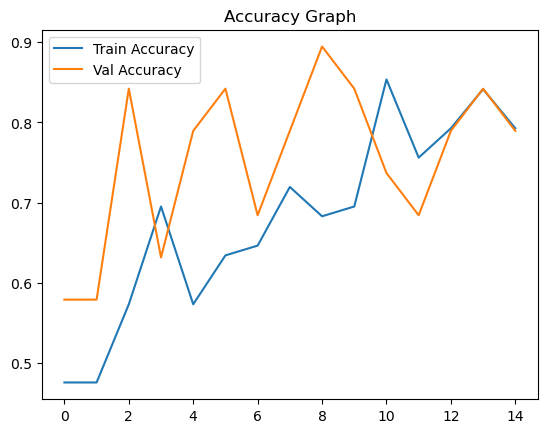

In [17]:
plt.plot(history.history['accuracy'], label = 'Train Accuracy')
plt.plot(history.history['val_accuracy'], label = 'Val Accuracy')
plt.legend()
plt.title("Accuracy Graph")
plt.show()

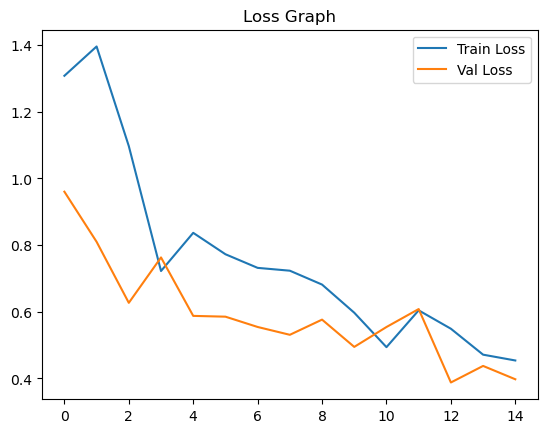

In [18]:
plt.plot(history.history['loss'], label = 'Train Loss')
plt.plot(history.history['val_loss'], label = 'Val Loss')
plt.legend()
plt.title("Loss Graph")
plt.show()
